# House Rent Prediction using Linear Regression

**Learning type:** Supervised Learning  
**Task:** Regression  
**Algorithm:** Linear Regression

## Goal
Predict monthly house rent from property details such as BHK, size, bathrooms, city, and furnishing status.

## Dataset required
Place a CSV file named `House_Rent_Dataset.csv` in the same folder as this notebook. The commonly used dataset includes columns such as `BHK`, `Rent`, `Size`, `Bathroom`, `City`, `Furnishing Status`, `Tenant Preferred`, `Area Type`, and `Point of Contact`.

If your CSV uses different column names, inspect the columns in Step 3 and update the feature list in Step 6. This notebook does not invent evaluation scores; metrics are calculated when you run it on your dataset.


## 1. Import libraries
These libraries help us load data, prepare it, train the model, evaluate it, and save it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Load the dataset
Put `House_Rent_Dataset.csv` beside this notebook before running the cell.

In [2]:
DATA_PATH = Path("house_rent.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "House_Rent_Dataset.csv was not found. Put the CSV file in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (10000, 9)


,city,bhk,size_sqft,bathrooms,property_type,furnishing,floor,property_age,rent
0,Kolkata,2,1271.0,2.0,Apartment,Fully Furnished,Low,3,51959
1,Hyderabad,2,872.0,2.0,Apartment,Fully Furnished,Middle,19,48865
2,Pune,4,1594.0,5.0,Apartment,Unfurnished,High,26,62189
3,Kolkata,2,1108.0,3.0,Apartment,Semi-Furnished,Low,28,45056
4,Bangalore,4,2296.0,4.0,Apartment,Semi-Furnished,Low,12,86286


## 3. Understand the data

- Each row represents one rental property.
- **Features (`X`)** are the property details used to predict rent.
- **Target (`y`)** is the `Rent` column, the value the model learns to predict.

## 4. Basic data cleaning
Remove spaces from column names, convert `Rent` to numeric, and remove rows with invalid or non-positive rent.

In [6]:
df.columns = df.columns.str.strip()

if "rent" not in df.columns:
    raise ValueError("Target column 'rent' was not found. Check the column names printed above.")

df["rent"] = pd.to_numeric(df["rent"], errors="coerce")
df = df.dropna(subset=["rent"])
df = df[df["rent"] > 0].copy()

print("Shape after basic cleaning:", df.shape)
display(df.head())


Shape after basic cleaning: (10000, 9)


,city,bhk,size_sqft,bathrooms,property_type,furnishing,floor,property_age,rent
0,Kolkata,2,1271.0,2.0,Apartment,Fully Furnished,Low,3,51959
1,Hyderabad,2,872.0,2.0,Apartment,Fully Furnished,Middle,19,48865
2,Pune,4,1594.0,5.0,Apartment,Unfurnished,High,26,62189
3,Kolkata,2,1108.0,3.0,Apartment,Semi-Furnished,Low,28,45056
4,Bangalore,4,2296.0,4.0,Apartment,Semi-Furnished,Low,12,86286


## 5. Explore the data
Look at the distribution of rent and, if available, the relationship between size and rent.

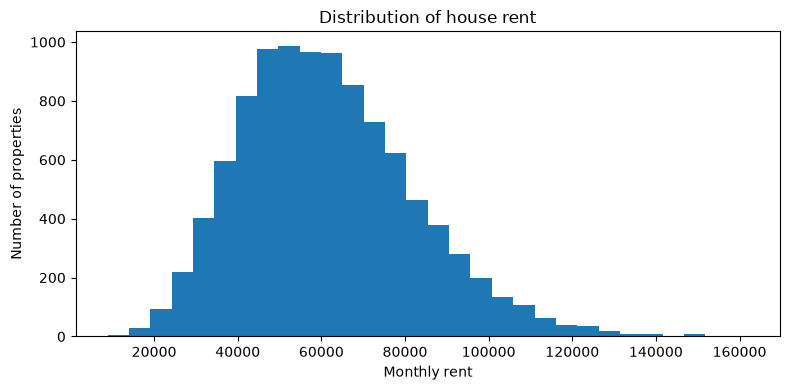

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(df["rent"], bins=30)
plt.xlabel("Monthly rent")
plt.ylabel("Number of properties")
plt.title("Distribution of house rent")
plt.tight_layout()
plt.show()

if "Size" in df.columns:
    df["Size"] = pd.to_numeric(df["Size"], errors="coerce")
    plt.figure(figsize=(7, 4))
    plt.scatter(df["Size"], df["rent"], alpha=0.5)
    plt.xlabel("Size (dataset unit)")
    plt.ylabel("Monthly rent")
    plt.title("House size vs rent")
    plt.tight_layout()
    plt.show()

if "City" in df.columns:
    display(df.groupby("City")["rent"].median().sort_values(ascending=False).to_frame("Median rent"))


## 6. Select features (`X`) and target (`y`)

We use the expected house-rent columns that are present in your CSV. `Rent` is the target to predict.

In [11]:
candidate_features = [
    "city",
    "bhk",
    "size_sqft",
    "bathrooms",
    "property_type",
    "furnishing",
    "floor",
    "property_age"
]

# Select only the feature columns available in the dataset
feature_columns = [
    column for column in candidate_features
    if column in df.columns
]

if not feature_columns:
    raise ValueError("No expected feature columns found. Check df.columns.")

# Input features
X = df[feature_columns].copy()

# Target variable
y = df["rent"].copy()

print("Features used:", feature_columns)
print("Target: rent")
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

Features used: ['city', 'bhk', 'size_sqft', 'bathrooms', 'property_type', 'furnishing', 'floor', 'property_age']
Target: rent
X shape: (10000, 8)
y shape: (10000,)


,city,bhk,size_sqft,bathrooms,property_type,furnishing,floor,property_age
0,Kolkata,2,1271.0,2.0,Apartment,Fully Furnished,Low,3
1,Hyderabad,2,872.0,2.0,Apartment,Fully Furnished,Middle,19
2,Pune,4,1594.0,5.0,Apartment,Unfurnished,High,26
3,Kolkata,2,1108.0,3.0,Apartment,Semi-Furnished,Low,28
4,Bangalore,4,2296.0,4.0,Apartment,Semi-Furnished,Low,12


0    51959
1    48865
2    62189
3    45056
4    86286
Name: rent, dtype: int64

## 7. Split into training and testing data

- **Training data:** used to learn patterns.
- **Testing data:** kept separate to evaluate predictions on unseen rows.

We use 80% for training and 20% for testing.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 8000
Testing rows: 2000


## 8. Preprocess the features

- Numerical columns: fill missing values with the median, then scale.
- Categorical columns: fill missing values with the most frequent category, then use One-Hot Encoding.
- A pipeline ensures the same transformations are used during training and prediction.

In [13]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['bhk', 'size_sqft', 'bathrooms', 'property_age']
Categorical features: ['city', 'property_type', 'furnishing', 'floor']


## 9. Train the Linear Regression model
Linear Regression learns a relationship between the property details and the numeric target, `Rent`.

In [14]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


## 10. Evaluate the model

- **MAE:** average absolute prediction error. Lower is better.
- **RMSE:** gives larger errors more weight. Lower is better.
- **R²:** measures fit relative to a simple mean-based baseline; closer to 1 is generally better, and it can be negative.

In [15]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.3f}")


MAE:  5,510.02
RMSE: 7,012.56
R²:   0.884


## 11. Compare actual rent with predicted rent

/var/folders/kb/5k24n_390rb3g3xwdn5nfft80000gn/T/ipykernel_10332/403167453.py:6: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  comparison["Absolute Error"] = (comparison["Actual Rent"] - comparison["Predicted Rent"]).abs()


,Actual Rent,Predicted Rent,Absolute Error
0,94093,77840.0,16253.0
1,57996,56592.0,1404.0
2,59784,59376.0,408.0
3,112736,99616.0,13120.0
4,65056,57632.0,7424.0
5,56812,59312.0,2500.0
6,74956,79600.0,4644.0
7,49382,57120.0,7738.0
8,62661,58336.0,4325.0
9,91838,94368.0,2530.0


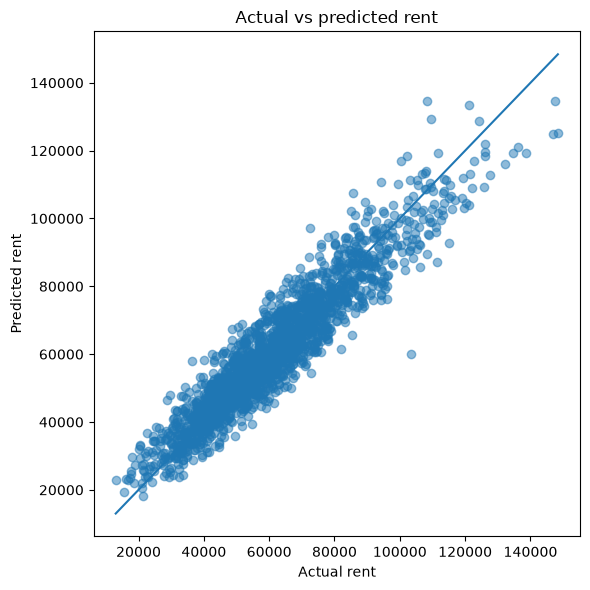

In [18]:
from IPython.core.display_functions import display
comparison = pd.DataFrame({
    "Actual Rent": y_test.to_numpy(),
    "Predicted Rent": y_pred
})
comparison["Absolute Error"] = (comparison["Actual Rent"] - comparison["Predicted Rent"]).abs()
display(comparison.head(10))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lower = min(float(y_test.min()), float(np.min(y_pred)))
upper = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([lower, upper], [lower, upper])
plt.xlabel("Actual rent")
plt.ylabel("Predicted rent")
plt.title("Actual vs predicted rent")
plt.tight_layout()
plt.show()


## 12. Predict rent for a new property

Edit these example values to match your dataset and the market you are studying. The input must include all feature columns selected in Step 6.

In [19]:
example_values = {
    "BHK": 2,
    "Size": 1000,
    "Bathroom": 2,
    "City": "Mumbai",
    "Furnishing Status": "Semi-Furnished",
    "Tenant Preferred": "Bachelors/Family",
    "Area Type": "Super Area",
    "Point of Contact": "Contact Owner"
}

new_house = {}
for column in feature_columns:
    if column in example_values:
        new_house[column] = example_values[column]
    else:
        modes = df[column].mode(dropna=True)
        new_house[column] = modes.iloc[0] if not modes.empty else np.nan

new_house_df = pd.DataFrame([new_house])
predicted_rent = model.predict(new_house_df)[0]

display(new_house_df)
print(f"Predicted monthly rent: {predicted_rent:,.2f}")


,city,bhk,size_sqft,bathrooms,property_type,furnishing,floor,property_age
0,Pune,2,350.0,2.0,Apartment,Semi-Furnished,Middle,8


Predicted monthly rent: 37,904.00


## 13. Save the complete trained pipeline
The saved file includes preprocessing and the Linear Regression model.

In [20]:
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

model_path = models_dir / "house_rent_linear_regression.pkl"
joblib.dump(model, model_path)
print(f"Model saved to: {model_path}")


Model saved to: models/house_rent_linear_regression.pkl


## 14. Load the saved model and test it

In [21]:
loaded_model = joblib.load(model_path)
loaded_prediction = loaded_model.predict(new_house_df)[0]
print(f"Prediction from saved model: {loaded_prediction:,.2f}")


Prediction from saved model: 37,904.00


## 15. What you should understand

1. **Why supervised learning?** The dataset contains known rent values.
2. **Why regression?** Rent is a numeric quantity.
3. **What are `X` and `y`?** `X` contains property details; `y` contains actual rent.
4. **Why split the data?** To evaluate on records not used during training.
5. **Why encode categories?** Linear Regression needs numeric inputs.
6. **Why use MAE, RMSE, and R²?** They measure prediction error and model fit.
7. **Why save the pipeline?** It keeps preprocessing and the trained model together.

### Limitations
- Predictions depend on the quality and coverage of the dataset.
- Basic Linear Regression may not capture complex rental-market patterns.
- Update the example input to match the dataset and region.
- Review the metrics before relying on predictions; successful training does not guarantee accuracy.
